# 02 · Feature extraction & FAISS indexing

Steps 1 and 2 of the approach:

1. **Image feature extraction** - pretrained CNN (ResNet50 / EfficientNet-B0), final
   classification layer removed, every photo → dense embedding vector.
2. **Embedding indexing** - store the embeddings and build an approximate-nearest-neighbour
   index with **FAISS** for millisecond search over ~59k photos.

Along the way I run an ablation to justify the preprocessing / pooling choices, and benchmark
exact vs approximate search on the real catalog.

In [1]:
import sys, time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import faiss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from PIL import Image
from sklearn.manifold import TSNE

import config
from src import database, indexer
from src.feature_extractor import ImageFolderDataset, build_backbone, extract_catalog_embeddings
from src.evaluation import leave_one_out_search, retrieval_metrics

sns.set_theme(style="whitegrid", context="notebook")
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("faiss", faiss.__version__)

images = pd.read_csv(config.IMAGES_CSV, dtype={"product_id": str})
paths = [config.CLEAN_IMAGE_DIR / f for f in images["file_name"]]
product_ids = images["product_id"].to_numpy()
categories = images["category"].to_numpy()
print(f"{len(images):,} photos of {images['product_id'].nunique():,} products")

torch 2.14.1+cu126 | CUDA: True | NVIDIA GeForce RTX 3060 Laptop GPU
faiss 1.15.1


58,891 photos of 11,311 products


## 1. Removing the classification head

Both networks end in a classifier over the 1,000 ImageNet classes. Those class scores are
specific to ImageNet's label set; the **pooled features right before the classifier** are a
general description of shape, texture and colour. I replace the classifier with
`nn.Identity()` so the network outputs that vector directly.

In [2]:
from torchvision import models
x = torch.randn(2, 3, 224, 224)
with torch.inference_mode():
    full = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2).eval()
    print("ResNet50 fc             :", full.fc, "->", tuple(full(x).shape))
    res = build_backbone("resnet50")
    print("ResNet50 headless       :", res.fc, "->", tuple(res(x).shape))
    full = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1).eval()
    print("EfficientNet-B0 head    :", full.classifier, "->", tuple(full(x).shape))
    eff = build_backbone("efficientnet_b0")
    print("EfficientNet-B0 headless:", eff.classifier, "->", tuple(eff(x).shape))
del full, res, eff

ResNet50 fc             : Linear(in_features=2048, out_features=1000, bias=True) -> (2, 1000)


ResNet50 headless       : Identity() -> (2, 2048)
EfficientNet-B0 head    : Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
) -> (2, 1000)


EfficientNet-B0 headless: Identity() -> (2, 1280)


**Design decisions in `FeatureExtractor`** (each one tested in the ablation in section 4):

* **Resize the whole photo to 224×224** - no center-crop, which could cut off part of the product.
* **L2-normalisation** - with unit vectors, *inner product = cosine similarity*, so a FAISS
  inner-product index performs exact cosine search.
* **Flip test-time augmentation** - average the embedding of the photo and its mirror image.
* **Mixed precision (fp16) for bulk extraction** on GPU, normalised in fp32 afterwards.
  Single-image queries in the app run in fp32 (see the note in `feature_extractor.py`).
* **Background data-loader workers** decode the next batch of JPEGs while the GPU works.

## 2. Extract embeddings for the whole catalog

In [3]:
embeddings, throughput = {}, []
for model_name in config.MODEL_DIMS:
    t0 = time.perf_counter()
    embeddings[model_name] = extract_catalog_embeddings(model_name, paths)
    database.register_embeddings(model_name, embeddings[model_name].shape[1], images["image_id"].tolist())
    secs = time.perf_counter() - t0
    throughput.append({"model": model_name, "dim": embeddings[model_name].shape[1],
                       "seconds": round(secs, 1), "images/sec": round(len(paths) / secs),
                       "file MB": round(config.embeddings_path(model_name).stat().st_size / 1e6)})
pd.DataFrame(throughput)

,model,dim,seconds,images/sec,file MB
0,resnet50,2048,147.1,400,482
1,efficientnet_b0,1280,119.2,494,302


In [4]:
for name, emb in embeddings.items():
    norms = np.linalg.norm(emb, axis=1)
    print(f"{name:16s} norms min={norms.min():.4f} max={norms.max():.4f}  "
          f"zeros={np.mean(emb == 0):.1%}  dtype={emb.dtype}")

resnet50         norms min=1.0000 max=1.0000  zeros=0.0%  dtype=float32


efficientnet_b0  norms min=1.0000 max=1.0000  zeros=0.0%  dtype=float32


All vectors have unit length, so cosine similarity is a plain dot product.

## 3. Does the embedding space make sense?

t-SNE of 4,000 random photos (EfficientNet-B0), coloured by category:

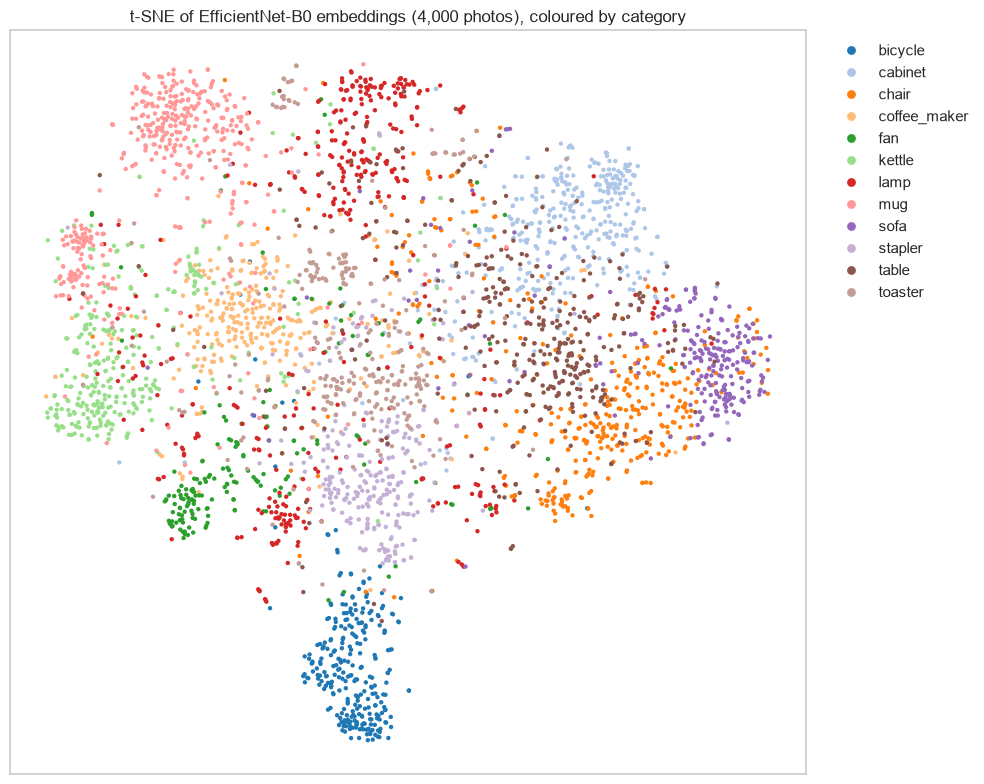

In [5]:
rng = np.random.default_rng(0)
sample = np.sort(rng.choice(len(images), 4000, replace=False))
emb = embeddings["efficientnet_b0"]
xy = TSNE(n_components=2, perplexity=40, init="pca", random_state=42).fit_transform(emb[sample])

fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=categories[sample], palette="tab20", s=10, linewidth=0, ax=ax)
ax.set_title("t-SNE of EfficientNet-B0 embeddings (4,000 photos), coloured by category")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, markerscale=2)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

Without ever seeing a label, the model separates most categories into their own regions.
**Bicycles** form an isolated island (nothing else has two spoked wheels), and **mugs,
kettles, fans, cabinets and sofas** each have their own area. The **furniture** categories
(chair / sofa / table / cabinet) border each other - they share wood, upholstery and living
room backgrounds. Lamps are the most scattered: table lamps, floor lamps, chandeliers and
lampshades look very different from each other.

How similar are two photos of the **same product** compared with two photos of the same
category, or of different categories?

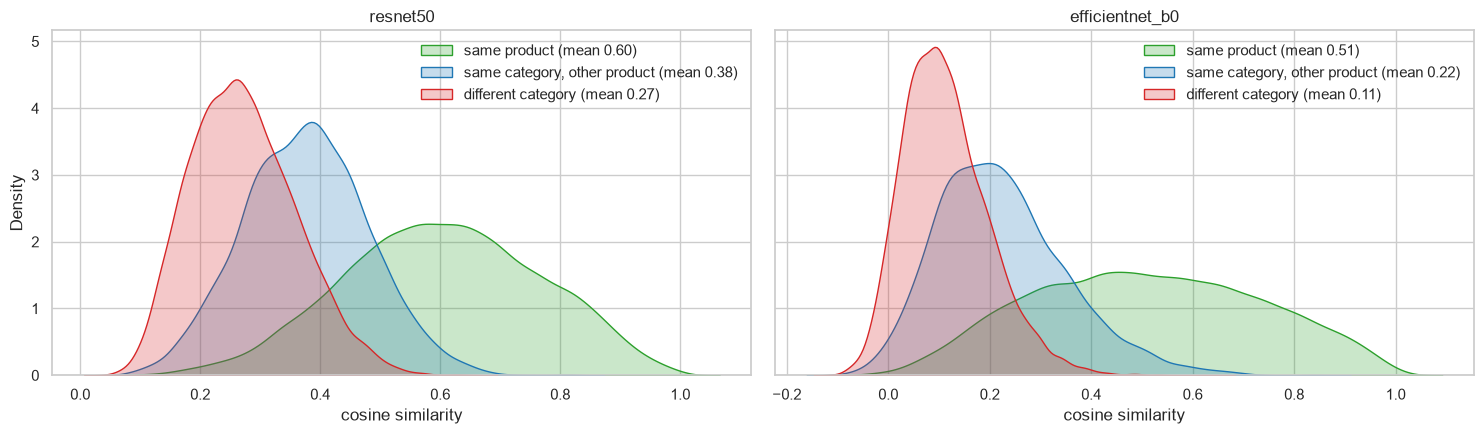

In [6]:
def pair_sims(emb, n=20000, seed=1):
    rng = np.random.default_rng(seed)
    # same product: random pairs of photos within products that have >= 2 photos
    multi = [v for v in images.groupby("product_id").indices.values() if len(v) > 1]
    picks = [rng.choice(multi[i], 2, replace=False) for i in rng.integers(0, len(multi), n)]
    same_prod = np.array([emb[a] @ emb[b] for a, b in picks])
    a, b = rng.integers(0, len(emb), (2, n * 3))
    sims = (emb[a] * emb[b]).sum(1)
    same_cat = sims[(categories[a] == categories[b]) & (product_ids[a] != product_ids[b])][:n]
    diff_cat = sims[categories[a] != categories[b]][:n]
    return same_prod, same_cat, diff_cat

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (name, emb_m) in zip(axes, embeddings.items()):
    sp, sc, dc = pair_sims(emb_m)
    for vals, label, colour in [(sp, "same product", "#2ca02c"), (sc, "same category, other product", "#1f77b4"),
                                (dc, "different category", "#d62728")]:
        sns.kdeplot(vals, ax=ax, label=f"{label} (mean {vals.mean():.2f})", color=colour, fill=True, alpha=0.25)
    ax.set_title(name)
    ax.set_xlabel("cosine similarity")
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Clear three-way ordering for both models: photos of the same product are far more similar than
photos of different products in the same category, which in turn beat different categories.
The overlap between the green and blue curves is where retrieval will make mistakes - two
different products in one category can look more alike than two views (front vs close-up) of
the same product.

## 4. Ablation - preprocessing, pooling and flip-TTA

Before committing to the design I compared variants of both backbones on a random subset of
**1,000 products** (all their photos), with exact search and the same leave-one-out metrics as
notebook 03.

In [7]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms as T

rng = np.random.default_rng(7)
subset_products = rng.choice(images["product_id"].unique(), 1000, replace=False)
sub = images[images["product_id"].isin(set(subset_products))].reset_index(drop=True)
sub_paths = [config.CLEAN_IMAGE_DIR / f for f in sub["file_name"]]
print(f"Ablation subset: {sub['product_id'].nunique()} products, {len(sub)} photos")

norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
transforms = {
    "resize 224x224": T.Compose([T.Resize((224, 224)), T.ToTensor(), norm]),
    "resize 256 + center-crop 224": T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), norm]),
}
device = "cuda" if torch.cuda.is_available() else "cpu"
trunks = {
    "resnet50": nn.Sequential(*list(models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2).children())[:-2]),
    "efficientnet_b0": models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1).features,
}
trunks = {k: v.eval().to(device) for k, v in trunks.items()}

def pool(fmap, kind):
    if kind == "avg":
        return fmap.mean((2, 3))
    return fmap.clamp(min=1e-6).pow(3).mean((2, 3)).pow(1 / 3)   # GeM, p=3

feats = {}   # (model, transform, pooling, flip) -> list of embedding chunks
with torch.inference_mode():
    for tf_name, tf in transforms.items():
        loader = DataLoader(ImageFolderDataset(sub_paths, tf), batch_size=128, num_workers=config.NUM_WORKERS)
        for batch in loader:
            batch = batch.to(device)
            for model_name, trunk in trunks.items():
                fmap, fmap_flip = trunk(batch), trunk(torch.flip(batch, dims=[3]))
                for kind in ["avg", "gem"]:
                    for flip in [False, True]:
                        f = pool(fmap, kind) + (pool(fmap_flip, kind) if flip else 0)
                        feats.setdefault((model_name, tf_name, kind, flip), []).append(
                            nn.functional.normalize(f.float(), dim=1).cpu().numpy())

rows = []
for (model_name, tf_name, kind, flip), chunks in feats.items():
    x = np.vstack(chunks).astype("float32")
    idx = faiss.IndexFlatIP(x.shape[1]); idx.add(x)
    s, _ = retrieval_metrics(leave_one_out_search(idx, x, 10), sub["product_id"].to_numpy(),
                             sub["category"].to_numpy(), [1, 10])
    o = s["overall"]
    rows.append({"model": model_name, "preprocessing": tf_name, "pooling": kind, "flip_tta": flip,
                 "product R@1": o["product_Hit@1"], "product R@10": o["product_Hit@10"],
                 "category P@10": o["category_P@10"]})
ablation = pd.DataFrame(rows).sort_values(["model", "product R@1"], ascending=[True, False]).reset_index(drop=True)
del trunks, feats
if torch.cuda.is_available():
    torch.cuda.empty_cache()
ablation.style.background_gradient(subset=["product R@1", "product R@10", "category P@10"], cmap="Greens").format(precision=3)

Ablation subset: 1000 products, 5197 photos


,model,preprocessing,pooling,flip_tta,product R@1,product R@10,category P@10
0,efficientnet_b0,resize 224x224,avg,False,0.715,0.851,0.744
1,efficientnet_b0,resize 224x224,avg,True,0.714,0.855,0.744
2,efficientnet_b0,resize 224x224,gem,True,0.697,0.838,0.726
3,efficientnet_b0,resize 224x224,gem,False,0.692,0.836,0.726
4,efficientnet_b0,resize 256 + center-crop 224,avg,True,0.674,0.823,0.725
5,efficientnet_b0,resize 256 + center-crop 224,avg,False,0.671,0.824,0.722
6,efficientnet_b0,resize 256 + center-crop 224,gem,False,0.665,0.816,0.705
7,efficientnet_b0,resize 256 + center-crop 224,gem,True,0.664,0.817,0.708
8,resnet50,resize 224x224,gem,True,0.747,0.875,0.747
9,resnet50,resize 224x224,gem,False,0.737,0.867,0.740


In [8]:
def effect(col, a, b, metric="product R@1"):
    others = [c for c in ["model", "preprocessing", "pooling", "flip_tta"] if c != col]
    pivot = ablation.pivot_table(index=others, columns=col, values=metric)
    return (pivot[b] - pivot[a]).groupby(level=0).mean().round(3)

pd.DataFrame({
    "resize vs center-crop": effect("preprocessing", "resize 256 + center-crop 224", "resize 224x224"),
    "GeM vs avg pooling": effect("pooling", "avg", "gem"),
    "flip-TTA on vs off": effect("flip_tta", False, True),
}).rename_axis("mean change in product R@1")

,resize vs center-crop,GeM vs avg pooling,flip-TTA on vs off
mean change in product R@1,,,
efficientnet_b0,0.036,-0.014,0.001
resnet50,0.046,0.040,0.007


**Reading the ablation** (product Recall@1 on the 1,000-product subset):

* **Resize beats center-crop for both backbones (+0.036 / +0.046).** Center-cropping cuts
  off parts of the product, which matters most for wide items like sofas and bicycles.
* **GeM pooling is backbone-dependent:** it lifts ResNet50 by **+0.040** (0.706 → 0.747) but
  lowers EfficientNet-B0 by 0.014. GeM (p=3) emphasises the strongest activations - usually
  the object rather than the background - which suits ResNet's wide 2048-channel maps.
* **Flip-TTA is roughly neutral** (+0.001 / +0.007). I keep it because its purpose is
  invariance for user uploads, not benchmark precision.

**Decision:** ResNet50 uses **GeM** pooling, EfficientNet-B0 keeps **average** pooling
(`config.MODEL_POOLING`), both with full-image resize and flip-TTA. The embeddings
extracted in section 2 already use these settings - in notebook 03 the change lifts
ResNet50's product Recall@1 on the full catalog from 0.559 (average pooling) to 0.602,
making it the best model.

## 5. Build the FAISS indexes

| Index | Type | Use |
|---|---|---|
| `IndexFlatIP` | exact, brute force | ground truth for ANN fidelity |
| `IndexHNSWFlat` (M=32, efConstruction=200, efSearch=128) | approximate graph | production search |

Both use inner product on unit vectors = cosine similarity.

In [9]:
built = {}
for model_name in config.MODEL_DIMS:
    t0 = time.perf_counter()
    built[model_name] = indexer.build_and_save_all(model_name)
    print(f"{model_name:16s} built in {time.perf_counter() - t0:5.1f}s  ->  " + ", ".join(
        f"{kind}: {config.index_path(model_name, kind).stat().st_size / 1e6:,.0f} MB" for kind in built[model_name]))

resnet50         built in  51.6s  ->  flat: 482 MB, hnsw: 498 MB


efficientnet_b0  built in  34.2s  ->  flat: 302 MB, hnsw: 318 MB


## 6. Exact vs approximate search on the real catalog

Single-query latency, and how often HNSW returns exactly the same top-10 as brute force, on
2,000 random catalog photos.

In [10]:
model_name = config.DEFAULT_MODEL
emb = embeddings[model_name]
flat, hnsw = built[model_name]["flat"], built[model_name]["hnsw"]
queries = np.sort(np.random.default_rng(3).choice(len(emb), 2000, replace=False))
_, exact = flat.search(emb[queries], 10)

def per_query_ms(index, n=500):
    t0 = time.perf_counter()
    for q in queries[:n]:
        index.search(emb[q:q + 1], 10)
    return (time.perf_counter() - t0) * 1000 / n

sweep = []
for ef in [16, 32, 64, 128, 256, 512]:
    hnsw.hnsw.efSearch = ef
    _, approx = hnsw.search(emb[queries], 10)
    sweep.append({"index": f"HNSW efSearch={ef}", "ms/query": per_query_ms(hnsw),
                  "recall@10 vs exact": np.mean([len(set(a) & set(e)) / 10 for a, e in zip(approx, exact)])})
hnsw.hnsw.efSearch = config.HNSW_EF_SEARCH
sweep.append({"index": "Flat (exact)", "ms/query": per_query_ms(flat), "recall@10 vs exact": 1.0})
sweep = pd.DataFrame(sweep)
sweep.style.format({"ms/query": "{:.3f}", "recall@10 vs exact": "{:.2%}"})

,index,ms/query,recall@10 vs exact
0,HNSW efSearch=16,0.432,98.68%
1,HNSW efSearch=32,0.556,99.59%
2,HNSW efSearch=64,0.985,99.85%
3,HNSW efSearch=128,1.579,99.96%
4,HNSW efSearch=256,3.027,99.98%
5,HNSW efSearch=512,5.542,100.00%
6,Flat (exact),37.514,100.00%


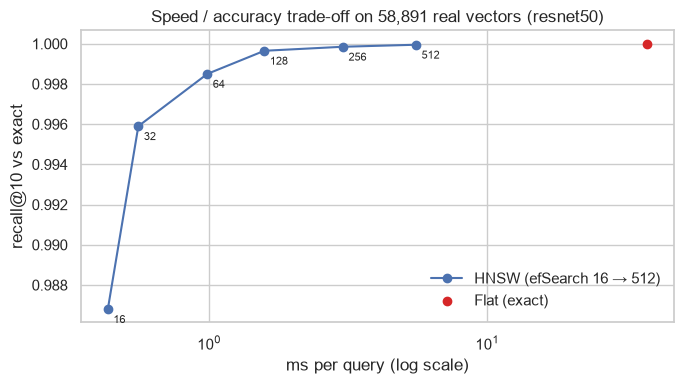

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
h = sweep[sweep["index"].str.startswith("HNSW")]
ax.plot(h["ms/query"], h["recall@10 vs exact"], "o-", label="HNSW (efSearch 16 → 512)")
for _, r in h.iterrows():
    ax.annotate(r["index"].split("=")[1], (r["ms/query"], r["recall@10 vs exact"]),
                textcoords="offset points", xytext=(4, -10), fontsize=8)
f = sweep[sweep["index"] == "Flat (exact)"].iloc[0]
ax.scatter([f["ms/query"]], [1.0], color="#d62728", zorder=3, label="Flat (exact)")
ax.set_xscale("log")
ax.set_xlabel("ms per query (log scale)"); ax.set_ylabel("recall@10 vs exact")
ax.set_title(f"Speed / accuracy trade-off on {len(emb):,} real vectors ({model_name})")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Reading the trade-off**

* Exact brute-force search over 58,891 × 2048-d vectors takes **~38 ms** per query.
* HNSW at the configured `efSearch=128` takes **~1.6 ms** (≈ 24× faster) and returns
  **99.96 %** of the exact top-10.
* Even the most aggressive setting (`efSearch=16`) still finds 98.7 % of the exact top-10 at
  under half a millisecond.

Brute-force cost grows linearly with the catalog, while HNSW grows roughly logarithmically,
so the gap widens for a million-product catalog. At this scale both are well inside the
sub-second requirement; the CNN forward pass, not the vector search, dominates end-to-end
latency.

## Summary

| Item | Result |
|---|---|
| Embeddings | 58,891 photos × ResNet50 (2048-d, GeM) and EfficientNet-B0 (1280-d, avg), L2-normalised |
| Extraction speed (RTX 3060 laptop, AMP, 4 loader workers) | ~400 img/s ResNet50, ~490 img/s EfficientNet-B0 |
| Embedding space | categories separate without labels; same-product photos clearly closer than same-category |
| Ablation | resize > center-crop; GeM for ResNet50 only; flip-TTA neutral |
| FAISS | Flat + HNSW per model; HNSW = 99.96 % of exact top-10 at ~1.6 ms vs ~38 ms |

Next notebook: similarity search, ranking/filtering and the full evaluation.